MAGOMU EMMANUEL


FIRST 8 ROWS OF THE DATASET


,default,revolving_utilization,age,NumberOfTime30-59DaysPastDueNotWorse,debt_ratio,MonthlyIncome,open_credit_lines,NumberOfTimes90DaysLate,real_estate_loans,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.000000,13,0,6,0,2.000000
1,0,0.957151,40,0,0.121876,2600.000000,4,0,0,0,1.000000
2,0,0.658180,38,1,0.085113,3042.000000,2,1,0,0,0.000000
3,0,0.233810,30,0,0.036050,3300.000000,5,0,0,0,0.000000
4,0,0.907239,49,1,0.024926,63588.000000,7,0,1,0,0.000000
5,0,0.213179,74,0,0.375607,3500.000000,3,0,1,0,1.000000
6,0,0.305682,57,0,5710.000000,nan,8,0,3,0,0.000000
7,0,0.754464,39,0,0.209940,3500.000000,8,0,0,0,0.000000



DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   default                               150000 non-null  int64  
 1   revolving_utilization                 150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   debt_ratio                            150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   open_credit_lines                     150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   real_estate_loans                     150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null 

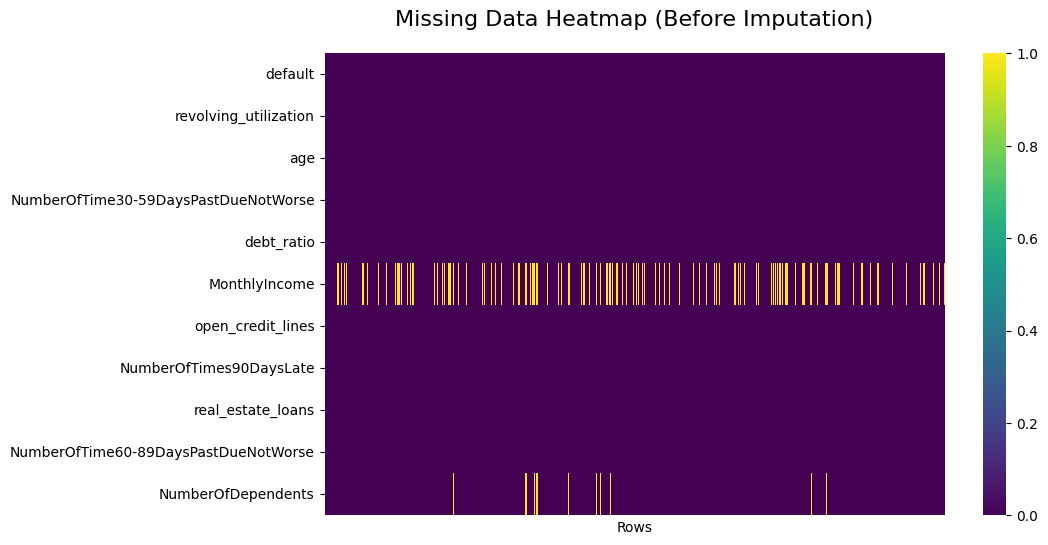

default                                     0
revolving_utilization                       0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
debt_ratio                                  0
MonthlyIncome                           29731
open_credit_lines                           0
NumberOfTimes90DaysLate                     0
real_estate_loans                           0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


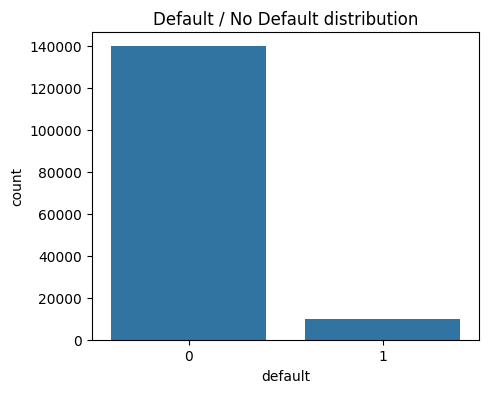

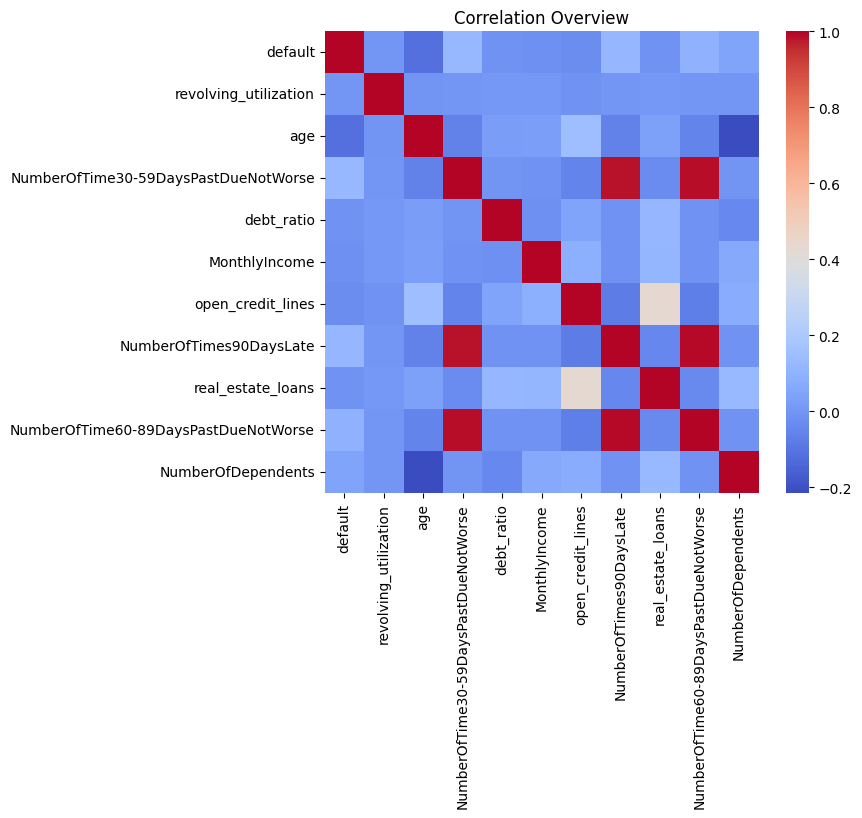

Chosen features:

['revolving_utilization', 'NumberOfTimes90DaysLate', 'NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'age', 'real_estate_loans', 'open_credit_lines', 'debt_ratio', 'MonthlyIncome', 'NumberOfDependents']


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import warnings
warnings.filterwarnings("ignore")


data = pd.read_csv("cs-training.csv")

#clean column names
data = data.rename(columns={
    'SeriousDlqin2yrs': 'default',
    'RevolvingUtilizationOfUnsecuredLines': 'revolving_utilization',
    'DebtRatio': 'debt_ratio',
    'NumberOfOpenCreditLinesAndLoans': 'open_credit_lines',
    'NumberRealEstateLoansOrLines': 'real_estate_loans'
})

#drop the index column
data = data.drop(['Unnamed: 0'], axis=1, errors='ignore')
data.head()

print("FIRST 8 ROWS OF THE DATASET")
display(data.head(8).style
        .format({
            'person_income': '${:,.0f}',
            'loan_amnt': '${:,.0f}',
            'loan_int_rate': '{:.2f}%',
            'loan_percent_income': '{:.1%}'
        })
        .set_caption("Table 1: Sample of Raw Credit Risk Data")
        .set_table_attributes("style='display:inline; font-size:14px;'")
        .background_gradient(cmap='viridis'))

print("\nDATASET INFO")
data.info()


#Handling missing values using median
# Missing values heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(data.isnull().T, cbar=True, cmap='viridis', yticklabels=True, xticklabels=False)
plt.title("Missing Data Heatmap (Before Imputation)", fontsize=16, pad=20)
plt.xlabel("Rows")
plt.show()

print(data.isnull().sum())
data['MonthlyIncome'] = data['MonthlyIncome'].fillna(data['MonthlyIncome'].median())
data['NumberOfDependents'] = data['NumberOfDependents'].fillna(data['NumberOfDependents'].median())

#Visualisation
plt.figure(figsize=(5,4))
sns.countplot(x=data['default'])
plt.title("Default / No Default distribution")
plt.show()

plt.figure(figsize=(7,6))
sns.heatmap(data.corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Overview")
plt.show()



#Feature selection
X = data.drop("default", axis=1)
y = data['default']

mi_scores = mutual_info_classif(X, y)
mi_df = pd.DataFrame({
    'feature': X.columns,
    'MI_score': mi_scores
}).sort_values(by='MI_score', ascending=False)

#10 features based on MI
top_features = mi_df.head(10)['feature'].tolist()
X = X[top_features]

print("Chosen features:\n")
print(top_features)




------ Logistic Regression ------
Accuracy: 0.934
              precision    recall  f1-score   support

           0       0.94      1.00      0.97     27995
           1       0.58      0.04      0.08      2005

    accuracy                           0.93     30000
   macro avg       0.76      0.52      0.52     30000
weighted avg       0.91      0.93      0.91     30000



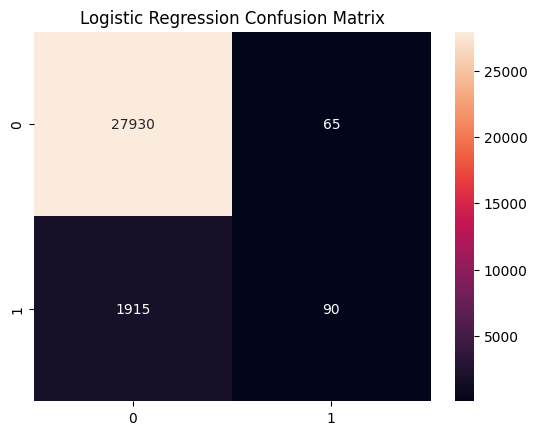

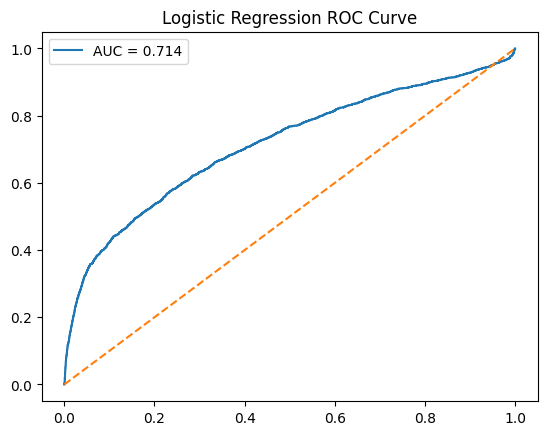


------ Random Forest ------
Accuracy: 0.9362
              precision    recall  f1-score   support

           0       0.94      0.99      0.97     27995
           1       0.57      0.19      0.28      2005

    accuracy                           0.94     30000
   macro avg       0.76      0.59      0.62     30000
weighted avg       0.92      0.94      0.92     30000



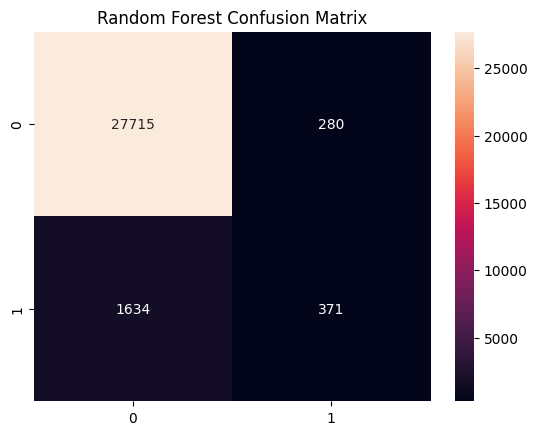

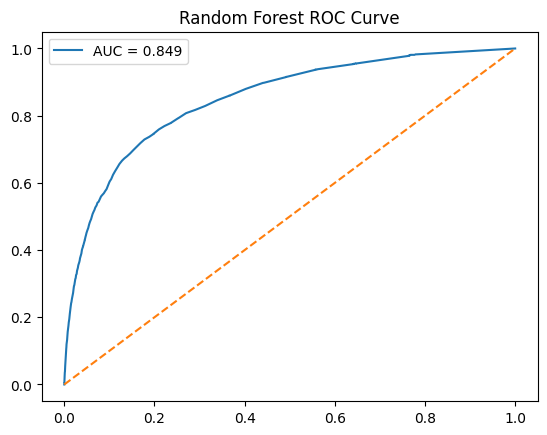

RF 5-fold AUC scores: [0.83876368 0.84489207 0.84576992 0.83903694 0.84893661]
Mean AUC: 0.8434798425288059

Feature Importance:

                                feature  importance
0                 revolving_utilization    0.192769
7                            debt_ratio    0.175514
8                         MonthlyIncome    0.147582
4                                   age    0.129023
6                     open_credit_lines    0.090586
1               NumberOfTimes90DaysLate    0.089062
2  NumberOfTime30-59DaysPastDueNotWorse    0.051322
3  NumberOfTime60-89DaysPastDueNotWorse    0.048228
9                    NumberOfDependents    0.041950
5                     real_estate_loans    0.033964


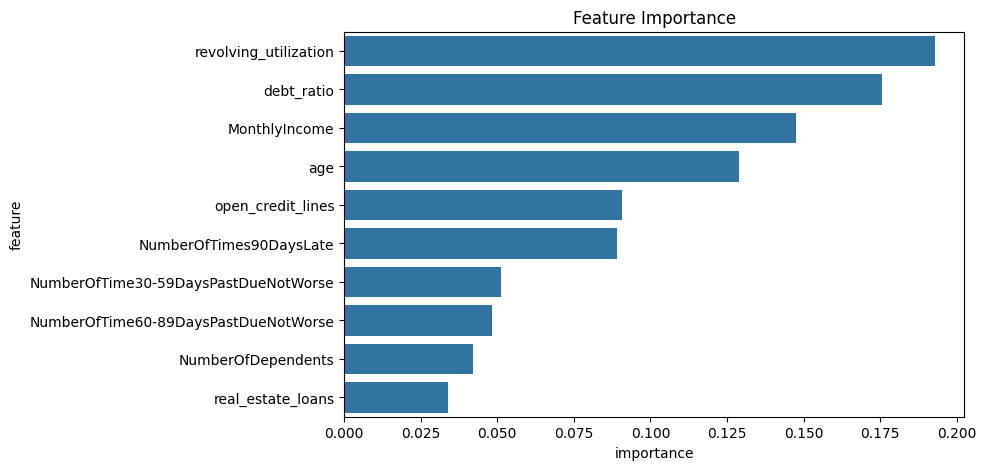

Model saved successfully.


In [20]:



# 5. Train-test split + scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

#Train models
#simple baseline
log_model = LogisticRegression(max_iter=300)
log_model.fit(X_train_s, y_train)

#main model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)
rf_model.fit(X_train_s, y_train)

#predictions
log_pred = log_model.predict(X_test_s)
rf_pred = rf_model.predict(X_test_s)

log_proba = log_model.predict_proba(X_test_s)[:,1]
rf_proba = rf_model.predict_proba(X_test_s)[:,1]


#Evaluation helper
def evaluate(model_name, y_true, y_pred, y_proba):
    print(f"\n------ {model_name} ------")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred))

    #confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title(model_name + " Confusion Matrix")
    plt.show()

    #ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
    plt.plot([0,1],[0,1], '--')
    plt.legend()
    plt.title(model_name + " ROC Curve")
    plt.show()

evaluate("Logistic Regression", y_test, log_pred, log_proba)
evaluate("Random Forest", y_test, rf_pred, rf_proba)

#Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rf = cross_val_score(rf_model, scaler.transform(X), y, cv=cv, scoring='roc_auc')

print("RF 5-fold AUC scores:", cv_rf)
print("Mean AUC:", np.mean(cv_rf))



# 9. Feature Importance from Random Forest
fi = pd.DataFrame({
    'feature': top_features,
    'importance': rf_model.feature_importances_
}).sort_values(by='importance', ascending=False)

print("\nFeature Importance:\n")
print(fi)

plt.figure(figsize=(8,5))
sns.barplot(data=fi, x='importance', y='feature')
plt.title("Feature Importance")
plt.show()



# 10. Saving model
import joblib
joblib.dump(rf_model, "loan_default_model.joblib")
joblib.dump(scaler, "scaler.joblib")

print("Model saved successfully.")
